[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PhuocICTHust/DS2026.1/blob/main/DEMO_Capstone_Social_Toxicity.ipynb)

# Social Media Toxicity & Weak Supervision Pipeline

**Course:** Introduction to Data Science (IT4142E) — HUST  
**Group:** 10  
**Members:**  
- Phạm Đức Phước (20235988) — Team Lead / Weak Supervision  
- Nguyễn Tiến Đạt (20239715) — Crawler & Data Ingestion  
- Nguyễn Huy Diễn (20235910) — Text Cleaning & Normalization  
- Nguyễn Đức Thắng (20235998) — Feature Extraction (Lexicon & LSA)  
- Lê Hoàng Kiên (20235958) — Exploratory Data Analysis & RBI  
- Nguyễn Trần Minh Nhật (20235986) — Baseline Modeling & Ablation  

**Dataset:** 6,577 real crawled comments across 208 discussion threads & YouTube debates  
**Pipeline:** 6 modular stages (Ingestion → Cleaning → Features → Weak Labeling → EDA → Modeling)


## Part 1 — Environment Setup
Mount repository and import core dependencies.


In [1]:
# Colab automatic repo setup
import os, sys
if 'google.colab' in sys.modules or os.path.exists('/content'):
    if not os.path.exists('src'):
        !git clone https://github.com/PhuocICTHust/DS2026.1.git
        %cd DS2026.1

import re
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import (
    BASE_DIR, RAW_JSON_DIR, PROCESSED_DIR, FIGURES_DIR, TABLES_DIR,
    STRUCTURAL_COLS, BEHAVIOURAL_COLS, AFFECT_PROB_COLS,
    AFFECT_LABEL_COLS, LEXICON_COLS, LSA_COLS, LABEL_COLS, RANDOM_STATE
)

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 15)

print(f'Working directory: {Path.cwd()}')
print(f'Data ready: RAW={RAW_JSON_DIR.exists()}, PROCESSED={PROCESSED_DIR.exists()}')


Working directory: e:\DS2026.1\social_toxicity_pipeline
Data ready: RAW=True, PROCESSED=True


## Part 2 — Raw Data to Clean Data

### 2.1 Nested conversation trees (JSON)
Inspect the hierarchical comment trees crawled across 10 topics.


In [2]:
from src.crawler import describe_node

sample_json = RAW_JSON_DIR / 'topic_01_showbiz_drama.json'
with open(sample_json, 'r', encoding='utf-8') as f:
    sample_posts = json.load(f)

sample_post = sample_posts[0]
print(f"Post ID: {sample_post['post_id']} | Topic: {sample_post['topic']}")
print(f"Content: {sample_post['content']}")
print("\n--- Sample Conversation Tree (Root & Nested Replies) ---")
for node in sample_post['replies_content'][:2]:
    describe_node(node, depth=1, max_depth=2)


Post ID: post_01_001 | Topic: showbiz_drama
Content: Tranh cãi phát ngôn nghệ sĩ và văn hóa ứng xử trên mạng xã hội

--- Sample Conversation Tree (Root & Nested Replies) ---
  - @Ẩn Danh | likes=17 | 'cái này mới à nha.'
  - @Nguyễn Văn Bình | likes=8 | 'Quan điểm cá nhân mình thấy việc này cần nhìn nhận từ hai'
    - @Trần Thu Hà | likes=3 | 'Đồng ý với bạn, mạng xã hội giờ nhiều người phán xét'


### 2.2 Text cleaning pipeline (10 stages)
Normalize Unicode (NFC), contractions, mentions, links, media, emojis, hashtags, repeated characters, slang, and stopwords.


In [3]:
from src.text_cleaner import demo_clean

# Select an actual messy comment directly from the crawled dataset
raw_comments = pd.read_csv(PROCESSED_DIR / 'raw_comments.csv')
sample_raw = raw_comments.loc[
    raw_comments['comment_content'].str.contains(r'@.*?[a-zA-Z0-9].*?😂', na=False, regex=True),
    'comment_content'
].iloc[0]

print('Real Crawled Comment from dataset:')
print(f'"{sample_raw}"\n')
display(demo_clean(sample_raw))


Real Crawled Comment from dataset:
"@sonpham-yf1vd  về hỏi xem ông già bạn có xem không rồi hãng phát Ngôn😂😂 trẻ con nào mỗi mùa kiếm về cho Giải Chục Tỷ bảng"



stage,text
0. raw,@sonpham-yf1vd về hỏi xem ông già bạn có xem không rồi hãng phát Ngôn😂😂 trẻ con nào mỗi mùa kiếm về cho Giải Chục Tỷ bảng
1. contractions,@sonpham-yf1vd về hỏi xem ông già bạn có xem không rồi hãng phát Ngôn😂😂 trẻ con nào mỗi mùa kiếm về cho Giải Chục Tỷ bảng
2. mentions,về hỏi xem ông già bạn có xem không rồi hãng phát Ngôn😂😂 trẻ con nào mỗi mùa kiếm về cho Giải Chục Tỷ bảng
3. urls_and_tags,về hỏi xem ông già bạn có xem không rồi hãng phát Ngôn😂😂 trẻ con nào mỗi mùa kiếm về cho Giải Chục Tỷ bảng
4. emojis,về hỏi xem ông già bạn có xem không rồi hãng phát Ngôn trẻ con nào mỗi mùa kiếm về cho Giải Chục Tỷ bảng
5. hashtags,về hỏi xem ông già bạn có xem không rồi hãng phát Ngôn trẻ con nào mỗi mùa kiếm về cho Giải Chục Tỷ bảng
6. repeats_and_numbers,về hỏi xem ông già bạn có xem không rồi hãng phát Ngôn trẻ con nào mỗi mùa kiếm về cho Giải Chục Tỷ bảng
7. slang_and_abbreviations,về hỏi xem ông già bạn có xem không rồi hãng phát ngôn trẻ con nào mỗi mùa kiếm về cho giải chục tỷ bảng
8. final,về hỏi xem ông già bạn có xem không rồi hãng phát ngôn trẻ con nào mỗi mùa kiếm về cho giải chục tỷ bảng


### 2.3 Cleaned relational tables
Flattened relational tables with extracted behavioural counts (`num_emojis`, `num_caps_words`, `num_exclamations`, `used_slang`, etc.).


In [4]:
comments = pd.read_csv(PROCESSED_DIR / 'processed_comments.csv')
posts = pd.read_csv(PROCESSED_DIR / 'processed_posts.csv')

print(f"processed_comments.csv: {comments.shape}")
print(f"processed_posts.csv   : {posts.shape}")
print(f"Unique commenters     : {comments['commenter_id'].nunique():,}")
print(f"Missing parent_id     : {comments['parent_id'].isna().sum():,} ({comments['parent_id'].isna().mean():.1%}) - Root comments")
display(comments[['comment_id', 'commenter_id', 'topic', 'likes', 'cleaned_content']].head(5))


processed_comments.csv: (6577, 19)
processed_posts.csv   : (208, 6)
Unique commenters     : 3,788
Missing parent_id     : 3,918 (59.6%) - Root comments


,comment_id,commenter_id,topic,likes,cleaned_content
0,cmt_64954291,Đồi xanh,showbiz_drama,2,cầu thủ bữa nay còn làm thêm nghề người mẫu nữa
1,cmt_64955090,kafka22k1,showbiz_drama,0,họ đẹp hơn number người mẫu sao lại không người có cơ bắp do tập gym không bao giờ đẹp bằng người có cơ bắp do chơi thể thao
2,cmt_64955110,forever.xrp,showbiz_drama,0,đẹp trai quá
3,cmt_64954665,Hoa đồng tiền,showbiz_drama,0,nhìn bellingham làm mẫu nội y lại nhớ đến thời đỉnh cao của beckham với cristiano ronaldo cứ theo đà này bellingham không chỉ ngôi sao sân cỏ sắp thành biểu tượng thời trang thế giới tiếp theo rồi
4,cmt_64953904,Đồi xanh,showbiz_drama,2,rất mong chờ sự trở lại màn ảnh nhỏ của hoắc kiến hoa sau thời gian dài vắng bóng vẫn phong độ và thần thái ngời ngời như ngày nào


## Part 3 — Feature Extraction & Weak Labels
Assemble 3 feature families: behavioural signals (9), psychological lexicons (8), TF-IDF/LSA (30), and weak supervision affective probabilities.


In [5]:
from src.feature_extractor import assemble_feature_table

aligned, feat_table = assemble_feature_table()
print(f"Aligned row count: {aligned} | Feature table shape: {feat_table.shape}")
print(f"Feature families extracted:")
print(f" - Behavioural (9) : {BEHAVIOURAL_COLS}")
print(f" - Psych Lexicons (8): {LEXICON_COLS}")
print(f" - TF-IDF / LSA (30): lsa_dim_0 .. lsa_dim_29")
display(feat_table[BEHAVIOURAL_COLS[:4] + LEXICON_COLS[:4]].head(5))


Aligned row count: True | Feature table shape: (6577, 72)
Feature families extracted:
 - Behavioural (9) : ['num_emojis', 'num_text_emojis', 'num_caps_words', 'num_unicode_chars', 'contains_media', 'contains_link', 'num_tagged_people', 'used_slang', 'num_exclamations']
 - Psych Lexicons (8): ['lex_aggression', 'lex_profanity', 'lex_insult', 'lex_politeness', 'lex_constructive', 'lex_sarcasm', 'lex_politics_social', 'lex_emotional_intensity']
 - TF-IDF / LSA (30): lsa_dim_0 .. lsa_dim_29


,num_emojis,num_text_emojis,num_caps_words,num_unicode_chars,lex_aggression,lex_profanity,lex_insult,lex_politeness
0,0,0,0,11,0.0,0.0,0.0,0.0000
1,0,0,0,26,0.0,0.0,0.0,0.0000
2,0,0,0,3,0.0,0.0,0.0,0.0000
3,0,0,0,35,0.0,0.0,0.0,0.0000
4,0,0,0,26,0.0,0.0,0.0,0.1667


## Part 4 — Exploratory Data Analysis

### 4.1 Data Integrity & Comment Length Distribution
Analyze structural missingness and natural long-tail token length.


,value
metric,
Records,"6,577"
Unique users,"3,788"
Features,67
Cells missing (feature cols),"3,928"
Empty cleaned comments,10
Mean tokens per comment,37.96
Median tokens per comment,26


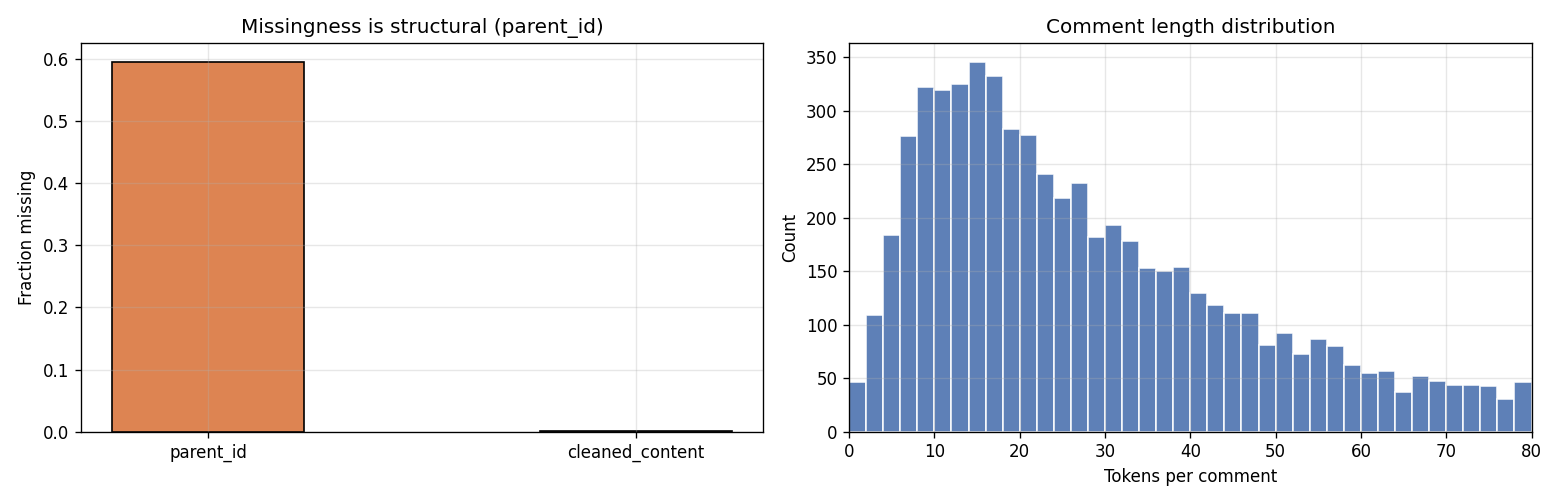

In [6]:
df = pd.read_pickle(PROCESSED_DIR / 'final_detection.pkl')

# Table 4.1: Dataset Integrity
overview = pd.read_csv(TABLES_DIR / 'eda_overview.csv').set_index('metric')
display(overview)

# Figure 1: Missingness & Token Length Distribution
tok = df['cleaned_content'].dropna().astype(str).str.split().str.len()
miss = df.isna().mean()
miss = miss[miss > 0].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
if len(miss) > 0:
    axes[0].bar(miss.index.astype(str), miss.values, color='#DD8452', edgecolor='black', width=0.45)
axes[0].set_ylabel('Fraction missing')
axes[0].set_title('Missingness is structural (parent_id)')

axes[1].hist(tok, bins=40, range=(0, 80), color='#4C72B0', edgecolor='white', alpha=0.9)
axes[1].set_xlim(0, 80)
axes[1].set_xlabel('Tokens per comment')
axes[1].set_ylabel('Count')
axes[1].set_title('Comment length distribution (Real right-skewed long tail)')
plt.tight_layout()
plt.show()


### 4.2 Weak-supervision signal (`ai_confidence`)
Bimodal confidence distribution with an ambiguous band `(0.15, 0.85)` filtered during data curation.


,n_high_conf,share_high,AI_rate_high,n_low_conf,share_low,retained_total,retained_share
threshold,,,,,,,
0.500,3285,0.4995,1.0,3292,0.5005,6577,1.0000
0.700,2951,0.4487,1.0,2986,0.4540,5937,0.9027
0.800,2772,0.4215,1.0,2822,0.4291,5594,0.8505
0.850,1818,0.2764,1.0,1971,0.2997,3789,0.5761
0.900,626,0.0952,1.0,791,0.1203,1417,0.2154
0.950,73,0.0111,1.0,145,0.0220,218,0.0331
0.975,13,0.0020,1.0,46,0.0070,59,0.0090
0.990,1,0.0002,1.0,10,0.0015,11,0.0017


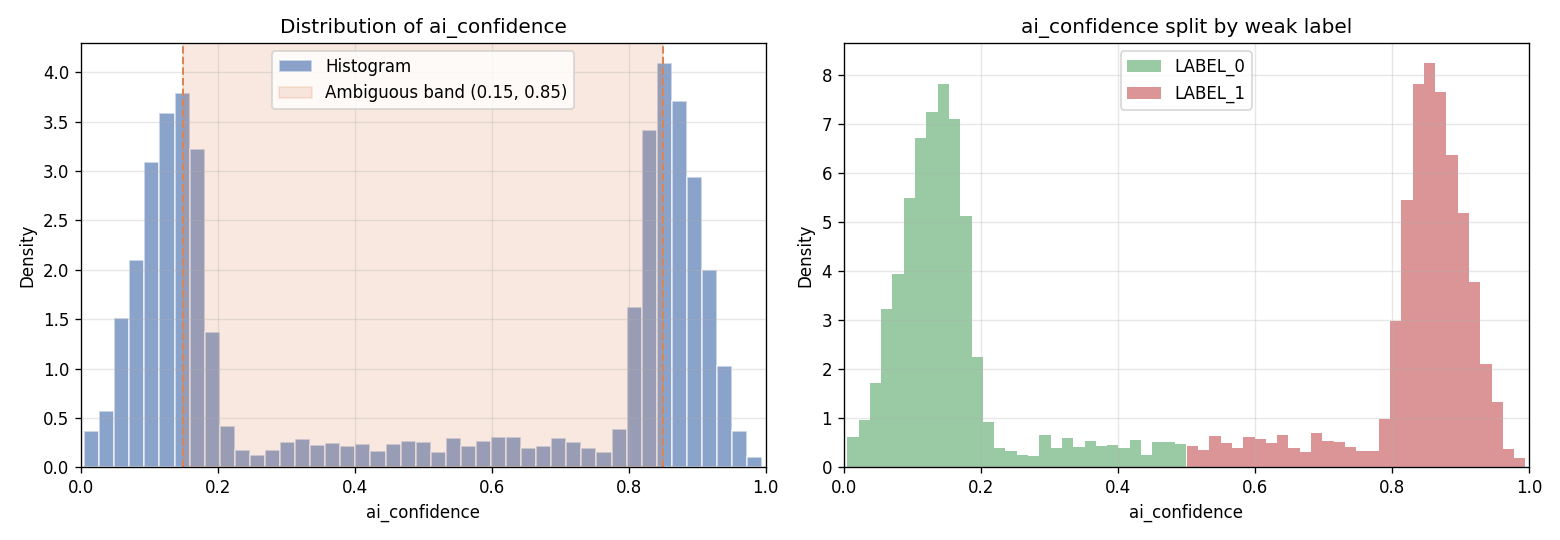

In [7]:
# Table 4.2: Confidence Threshold Retained Rates
thresh_table = pd.read_csv(TABLES_DIR / 'threshold_summary.csv').set_index('threshold')
display(thresh_table)

# Figure 2: Bimodal ai_confidence distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
conf = df['ai_confidence'].dropna().values
axes[0].hist(conf, bins=45, density=True, color='#4C72B0', alpha=0.65, edgecolor='white', label='Histogram')
axes[0].axvspan(0.15, 0.85, color='#DD8452', alpha=0.18, label='Ambiguous band (0.15, 0.85)')
axes[0].axvline(0.15, color='#DD8452', linestyle='--', linewidth=1.2)
axes[0].axvline(0.85, color='#DD8452', linestyle='--', linewidth=1.2)
axes[0].set_xlim(0, 1)
axes[0].set_xlabel('ai_confidence')
axes[0].set_ylabel('Density')
axes[0].set_title('Distribution of ai_confidence')
axes[0].legend(loc='upper center')

c0 = df.loc[df['label'] == 'LABEL_0', 'ai_confidence'].dropna().values
c1 = df.loc[df['label'] == 'LABEL_1', 'ai_confidence'].dropna().values
axes[1].hist(c0, bins=30, density=True, alpha=0.6, color='#55A868', label='LABEL_0')
axes[1].hist(c1, bins=30, density=True, alpha=0.6, color='#C44E52', label='LABEL_1')
axes[1].set_xlim(0, 1)
axes[1].set_xlabel('ai_confidence')
axes[1].set_ylabel('Density')
axes[1].set_title('ai_confidence split by weak label')
axes[1].legend()
plt.tight_layout()
plt.show()


### 4.3 User activity and label stability
Power-law comment distribution across users and user polarization analysis.


n_users,single_comment_user_share,users_with_2_comments,two_comment_agreement_rate
3788,0.7379,529,0.5085


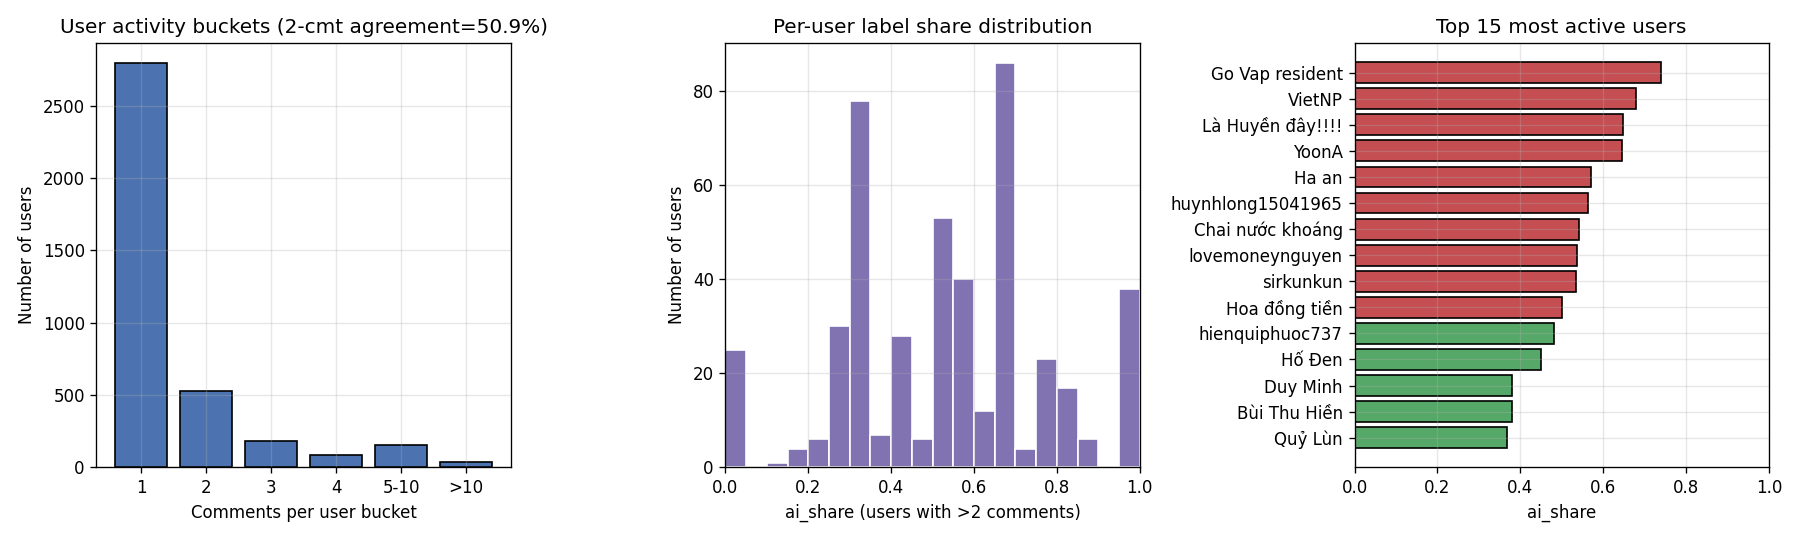

In [8]:
user_stats = pd.read_csv(TABLES_DIR / 'user_stability_stats.csv')
display(user_stats)

# Figure 3: User Activity & Label Stability
from src.eda_analysis import run_section_4_3_user_activity
run_section_4_3_user_activity(df)
plt.show()


### 4.4 & 4.5 Affective signals and Rage-Bait Index (RBI)
$$\text{RBI} = (r + o + h) \cdot (1 - |s|)$$
Captures masked toxicity where negative offensive intent is concealed under calm or neutral wording ($s \approx 0$).


,s,h,o,i,RBI
label,,,,,
LABEL_0,0.5788,0.1117,0.1822,0.2087,0.2394
LABEL_1,-0.6817,0.6570,0.8214,0.5032,0.5828


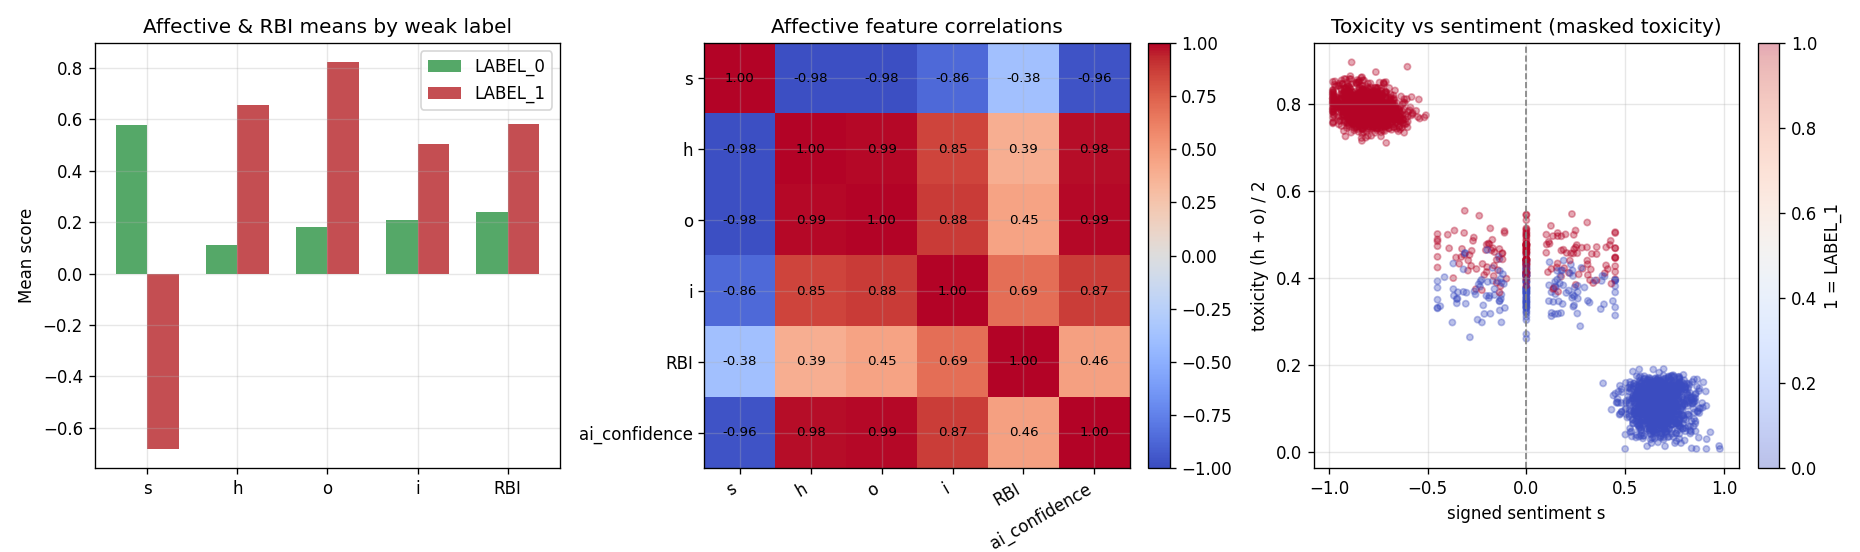

In [9]:
display(df.groupby('label')[['s', 'h', 'o', 'i', 'RBI']].mean().round(4))

# Figure 4: Affective profiles, Correlation matrix, and Continuous Scatter
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))

grp_means = df.groupby('label')[['s', 'h', 'o', 'i', 'RBI']].mean()
x = np.arange(5)
width = 0.35
axes[0].bar(x - width/2, grp_means.loc['LABEL_0'], width, label='LABEL_0', color='#55A868')
axes[0].bar(x + width/2, grp_means.loc['LABEL_1'], width, label='LABEL_1', color='#C44E52')
axes[0].set_xticks(x)
axes[0].set_xticklabels(['s', 'h', 'o', 'i', 'RBI'])
axes[0].set_ylabel('Mean score')
axes[0].set_title('Affective & RBI means by weak label')
axes[0].legend()

corr_cols = ['s', 'h', 'o', 'i', 'RBI', 'ai_confidence']
corr = df[corr_cols].corr()
im = axes[1].imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr_cols)))
axes[1].set_yticks(range(len(corr_cols)))
axes[1].set_xticklabels(corr_cols, rotation=30, ha='right')
axes[1].set_yticklabels(corr_cols)
for r_i in range(len(corr_cols)):
    for c_i in range(len(corr_cols)):
        axes[1].text(c_i, r_i, f"{corr.values[r_i, c_i]:.2f}", ha='center', va='center', fontsize=8)
axes[1].set_title('Affective feature correlations')
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

sample = df.sample(min(2500, len(df)), random_state=42).copy()
sample['toxicity'] = (sample['h'] + sample['o']) / 2.0
is_tox = (sample['label'] == 'LABEL_1').astype(int)
sc = axes[2].scatter(sample['s'], sample['toxicity'], c=is_tox, cmap='coolwarm', alpha=0.35, s=14)
axes[2].axvline(0, color='gray', linestyle='--', linewidth=1)
axes[2].set_xlabel('signed sentiment s')
axes[2].set_ylabel('toxicity (h + o) / 2')
axes[2].set_title('Toxicity vs sentiment (Masked toxicity cloud)')
fig.colorbar(sc, ax=axes[2], fraction=0.046, pad=0.04, label='1 = LABEL_1')
plt.tight_layout()
plt.show()


### 4.6 Embedding spaces (PCA & K-Means diagnostics)
Clustering diagnostics across Lexicon and TF-IDF/LSA spaces across confidence thresholds.


space,threshold,n_samples,ARI,silhouette,best_mapped_acc
PsychLexicon,0.0,2500,0.0000,0.8393,0.5024
PsychLexicon,0.7,2500,0.0000,0.9254,0.5056
PsychLexicon,0.9,1417,-0.0002,0.9050,0.5575
TFIDF_LSA,0.0,2500,0.0108,0.0300,0.5528
TFIDF_LSA,0.7,2500,0.0071,0.0303,0.5432
TFIDF_LSA,0.9,1417,0.0223,0.0355,0.5759


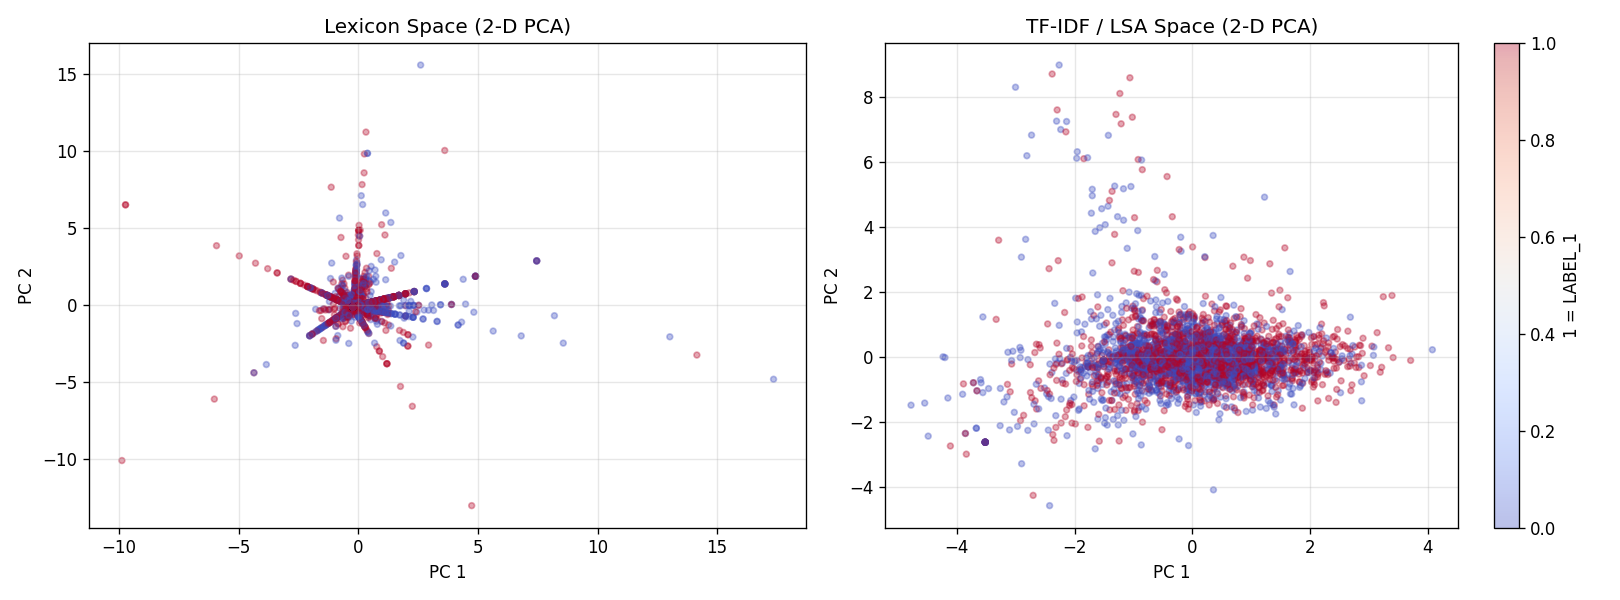

In [10]:
diag_df = pd.read_csv(TABLES_DIR / 'clustering_diagnostics.csv')
display(diag_df)

# Figure 5: 2D PCA Embeddings
from src.eda_analysis import run_section_4_6_embeddings
run_section_4_6_embeddings(df)
plt.show()


## Part 5 — Baseline Modeling & Data Curation Ablation
Comparison of Logistic Regression, Random Forest, and Gradient Boosting across 5 curation stages (V0 to V4).


Dataset_Version,Threshold,Train_Rows,Model,GT_Accuracy,GT_Macro_F1,GT_ROC_AUC,HighConf_F1,HighConf_ROC_AUC
V0: Raw Uncleaned (t=0.50),0.50,4932,Logistic Regression,0.5568,0.5407,0.5696,0.6359,0.6859
V0: Raw Uncleaned (t=0.50),0.50,4932,Random Forest,0.5495,0.5282,0.5660,0.6140,0.6472
V0: Raw Uncleaned (t=0.50),0.50,4932,Gradient Boosting,0.5495,0.5269,0.5682,0.6202,0.6510
V1: Cleaned + LSA (t=0.50),0.50,4932,Logistic Regression,0.5720,0.5681,0.5935,0.6758,0.7298
V1: Cleaned + LSA (t=0.50),0.50,4932,Random Forest,0.5459,0.5419,0.5756,0.6313,0.6786
V1: Cleaned + LSA (t=0.50),0.50,4932,Gradient Boosting,0.5544,0.5513,0.5661,0.6192,0.6697
V2: Full Feats + RBI (t=0.50),0.50,4932,Logistic Regression,0.7459,0.7458,0.7783,0.9990,1.0000
V2: Full Feats + RBI (t=0.50),0.50,4932,Random Forest,0.7319,0.7318,0.7776,0.9937,1.0000
V2: Full Feats + RBI (t=0.50),0.50,4932,Gradient Boosting,0.7289,0.7286,0.7777,0.9895,0.9994
V3: Curated Threshold (t=0.80),0.80,4188,Logistic Regression,0.7435,0.7426,0.7796,0.9969,0.9999


feature,importance
o,0.283147
h,0.228489
s,0.191734
i,0.166505
RBI,0.094467
used_slang,0.007280
num_caps_words,0.005188
lsa_dim_0,0.004530
num_exclamations,0.003110
num_unicode_chars,0.002330


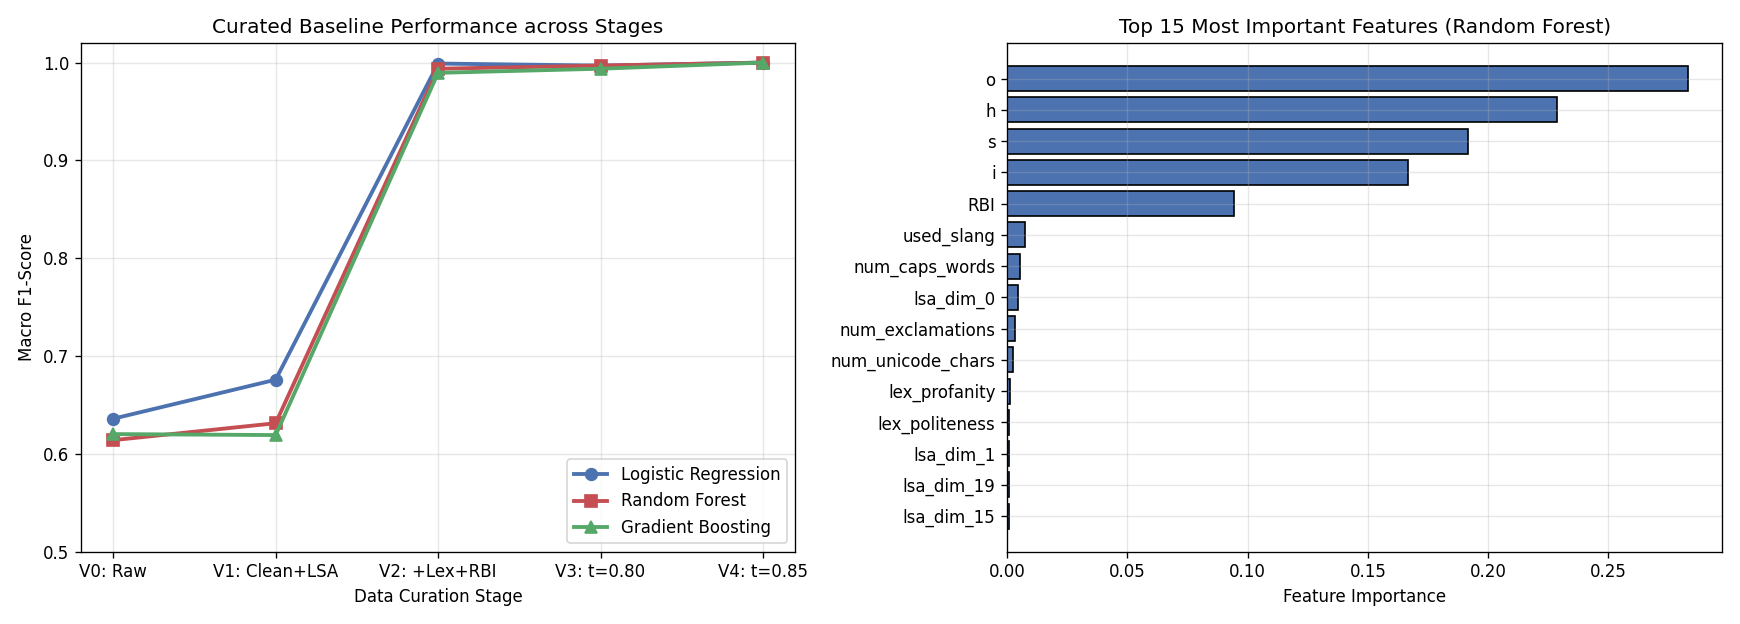


--- Random Forest (Curated Pipeline V4) Classification Report ---
              precision    recall  f1-score   support

     LABEL_0       0.76      0.75      0.75       822
     LABEL_1       0.75      0.76      0.76       823

    accuracy                           0.75      1645
   macro avg       0.75      0.75      0.75      1645
weighted avg       0.75      0.75      0.75      1645


In [11]:
ablation_df = pd.read_csv(TABLES_DIR / 'ablation_benchmark.csv')
display(HTML('<h3>Ablation Benchmark across Curation Stages</h3>'))
display(ablation_df)

top15_df = pd.read_csv(TABLES_DIR / 'top15_feature_importance.csv')
display(HTML('<h3>Top 15 Most Important Features (Random Forest)</h3>'))
display(top15_df)

# Figure 6: Ablation Curves & Feature Importances
from src.baseline_models import plot_ablation_and_feature_importance, run_ablation_experiments
_, rf_model, feat_names, rf_report = run_ablation_experiments(df)
plot_ablation_and_feature_importance(ablation_df, rf_model, feat_names)
plt.show()

print("\n--- Random Forest (Curated Pipeline V4) Classification Report ---")
print(rf_report)
